# 01 — Exploratory Data Analysis (EDA): Rossmann Store 1

**Project:** *An LSTM-Based Demand Forecasting and Inventory Optimization System for Retail Supply Chain Management*

## Mục tiêu

Notebook này thực hiện EDA ở phạm vi **Store 1**, thống nhất với `src/data.py` và `src/features.py`. Phân tích tập trung vào chất lượng dữ liệu, doanh thu theo thời gian, lịch, khuyến mãi và tính liên tục của chuỗi — những yếu tố có liên quan trực tiếp đến việc dự báo Sales bằng LSTM.

> EDA dùng để hiểu và kiểm tra dữ liệu, không bắt buộc phải thay đổi quyết định chọn Store 1. Bộ dữ liệu cung cấp doanh thu (`Sales`), không trực tiếp cung cấp tồn kho hay chi phí vận hành; các nội dung tối ưu tồn kho cần dữ liệu hoặc giả định bổ sung.

## 1. Chuẩn bị môi trường và nạp dữ liệu

Notebook hỗ trợ cấu trúc repo trong đó `data/train.csv` và `data/test.csv` nằm ở thư mục gốc, còn notebook nằm trong `notebooks/`. Nếu cấu trúc khác, hãy chỉnh `DATA_DIR` thủ công.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (11, 4)

CANDIDATE_DATA_DIRS = [Path("../data"), Path("data"), Path("../../data")]
DATA_DIR = next(
    (p.resolve() for p in CANDIDATE_DATA_DIRS
     if (p / "train.csv").exists() and (p / "test.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy train.csv và test.csv. Hãy chỉnh DATA_DIR cho đúng vị trí thư mục data."
    )

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
STORE_ID = 1

train_all = pd.read_csv(TRAIN_PATH, low_memory=False)
test_all = pd.read_csv(TEST_PATH, low_memory=False)
train_all.columns = train_all.columns.str.strip()
test_all.columns = test_all.columns.str.strip()

# Phạm vi nghiên cứu đã được xác định trước: chỉ phân tích Store 1.
train = train_all.loc[train_all["Store"] == STORE_ID].copy()
test = test_all.loc[test_all["Store"] == STORE_ID].copy()

for df in (train, test):
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df.sort_values("Date", inplace=True)
    df.reset_index(drop=True, inplace=True)

if train.empty:
    raise ValueError(f"Không tìm thấy dữ liệu train cho Store {STORE_ID}.")

print(f"Store được phân tích: {STORE_ID}")
print(f"Train: {len(train):,} dòng | Test: {len(test):,} dòng")
print(f"Train dates: {train['Date'].min()} → {train['Date'].max()}")
if not test.empty:
    print(f"Test dates : {test['Date'].min()} → {test['Date'].max()}")
display(train.head())

Store được phân tích: 1
Train: 942 dòng | Test: 48 dòng
Train dates: 2013-01-01 00:00:00 → 2015-07-31 00:00:00
Test dates : 2015-08-01 00:00:00 → 2015-09-17 00:00:00


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,2,2013-01-01,0,0,0,0,a,1
1,1,3,2013-01-02,5530,668,1,0,0,1
2,1,4,2013-01-03,4327,578,1,0,0,1
3,1,5,2013-01-04,4486,619,1,0,0,1
4,1,6,2013-01-05,4997,635,1,0,0,1


## 2. Chất lượng và tính nhất quán của dữ liệu

Kiểm tra giá trị thiếu, ngày không hợp lệ và khóa `(Store, Date)` trùng lặp. Những kiểm tra này tương ứng trực tiếp với các bước xác thực dữ liệu trong `data.py`.

In [2]:
quality = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "missing_count": train.isna().sum(),
    "missing_pct": (train.isna().mean() * 100).round(2),
    "unique_values": train.nunique(dropna=True),
}).sort_values("missing_count", ascending=False)
display(quality)

print("Ngày không hợp lệ trong train:", int(train["Date"].isna().sum()))
print("Dòng trùng hoàn toàn trong train:", int(train.duplicated().sum()))
print("Khóa Store-Date trùng trong train:", int(train.duplicated(["Store", "Date"]).sum()))
print("Sales bị thiếu:", int(train["Sales"].isna().sum()))
print("Sales âm:", int((train["Sales"] < 0).sum()))

if not test.empty:
    print("Ngày không hợp lệ trong test:", int(test["Date"].isna().sum()))
    print("Khóa Store-Date trùng trong test:", int(test.duplicated(["Store", "Date"]).sum()))
    display(pd.DataFrame({
        "train_missing": train.isna().sum(),
        "test_missing": test.isna().sum(),
    }).fillna(0).astype(int))

,dtype,missing_count,missing_pct,unique_values
Store,int64,0,0.00,1
DayOfWeek,int64,0,0.00,7
Date,datetime64[ns],0,0.00,942
Sales,int64,0,0.00,711
Customers,int64,0,0.00,305
Open,int64,0,0.00,2
Promo,int64,0,0.00,2
StateHoliday,object,0,0.00,4
SchoolHoliday,int64,0,0.00,2


Ngày không hợp lệ trong train: 0
Dòng trùng hoàn toàn trong train: 0
Khóa Store-Date trùng trong train: 0
Sales bị thiếu: 0
Sales âm: 0
Ngày không hợp lệ trong test: 0
Khóa Store-Date trùng trong test: 0


,train_missing,test_missing
Customers,0,0
Date,0,0
DayOfWeek,0,0
Id,0,0
Open,0,0
Promo,0,0
Sales,0,0
SchoolHoliday,0,0
StateHoliday,0,0
Store,0,0


**Cần ghi nhận:** không tự động thay `Sales` bị thiếu bằng 0 vì thiếu nhãn không đồng nghĩa với doanh thu bằng 0. `Customers` có thể được dùng để mô tả dữ liệu lịch sử, nhưng không nên dùng làm đầu vào dự báo trên test chính thức vì cột này không có trong test.

## 3. Phân phối Sales và trạng thái mở cửa

Phần này giúp hiểu độ phân tán của biến mục tiêu và kiểm tra mối liên hệ nghiệp vụ giữa `Open` và `Sales`.

Thống kê Sales:


,Sales
count,942.00
mean,"3,945.70"
std,"2,015.42"
min,0.00
25%,"3,588.25"
50%,"4,373.50"
75%,"5,220.00"
95%,"6,380.80"
99%,"7,806.24"
max,"9,528.00"


Sales bằng 0: 161
Sales nhỏ hơn 0: 0


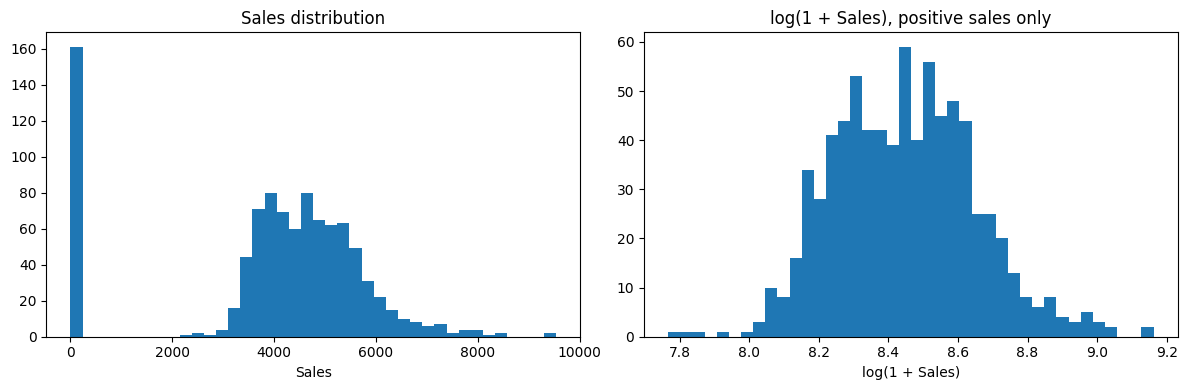

,count,mean,median,min,max
Open,,,,,
0,161,0.00,0.00,0,0
1,781,"4,759.10","4,647.00",2362,9528


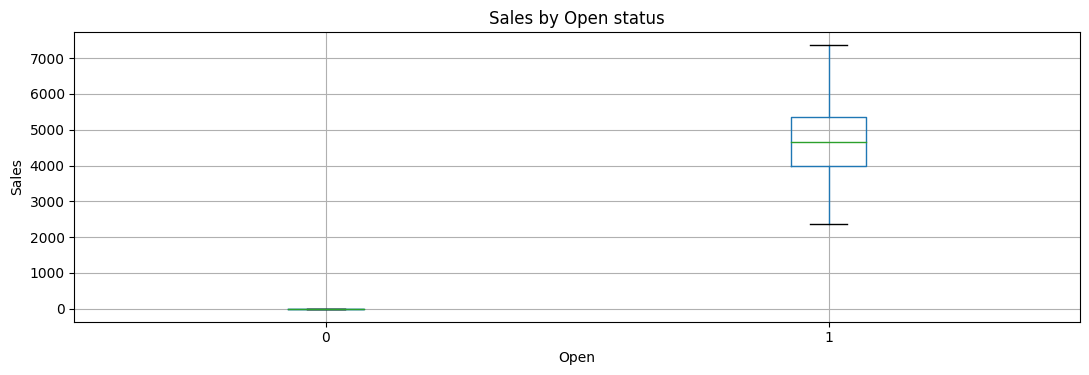

In [3]:
print("Thống kê Sales:")
display(train["Sales"].describe(percentiles=[.25, .5, .75, .95, .99]).to_frame())
print("Sales bằng 0:", int((train["Sales"] == 0).sum()))
print("Sales nhỏ hơn 0:", int((train["Sales"] < 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train["Sales"].dropna(), bins=40)
axes[0].set_title("Sales distribution")
axes[0].set_xlabel("Sales")
positive_sales = train.loc[train["Sales"] > 0, "Sales"].dropna()
axes[1].hist(np.log1p(positive_sales), bins=40)
axes[1].set_title("log(1 + Sales), positive sales only")
axes[1].set_xlabel("log(1 + Sales)")
plt.tight_layout()
plt.show()

if {"Open", "Sales"}.issubset(train.columns):
    display(train.groupby("Open", dropna=False)["Sales"].agg(
        count="count", mean="mean", median="median", min="min", max="max"
    ))
    train.boxplot(column="Sales", by="Open", showfliers=False)
    plt.title("Sales by Open status")
    plt.suptitle("")
    plt.xlabel("Open")
    plt.ylabel("Sales")
    plt.tight_layout()
    plt.show()

**Diễn giải:** xem doanh thu bằng 0 có tập trung ở những ngày `Open = 0` hay không. Nếu có, trạng thái mở cửa là thông tin quan trọng khi phân tích kết quả dự báo. Không tự ý loại bỏ các ngày doanh thu bằng 0 nếu chưa xác định nguyên nhân.

## 4. Xu hướng Sales theo thời gian

Chỉ vẽ doanh thu của Store 1, không cộng gộp nhiều cửa hàng. Đây là phân tích trung tâm cho bài toán dự báo chuỗi thời gian.

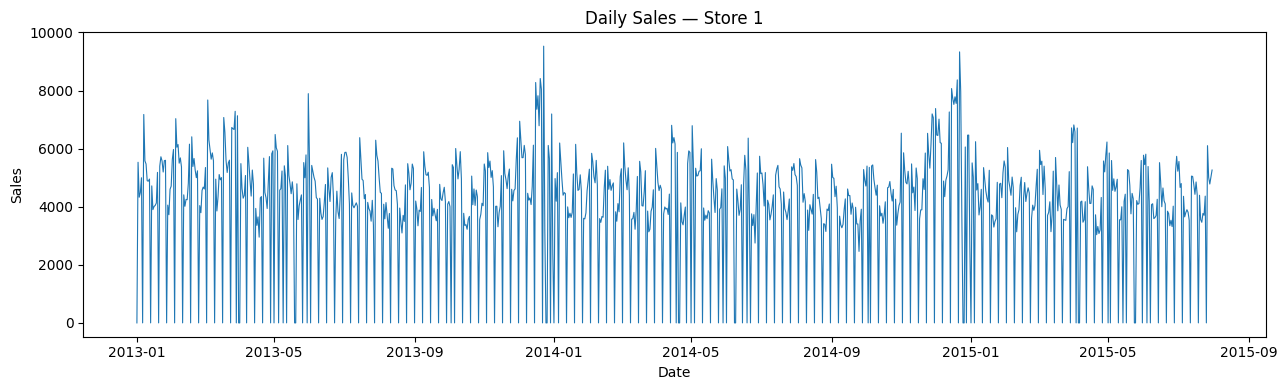

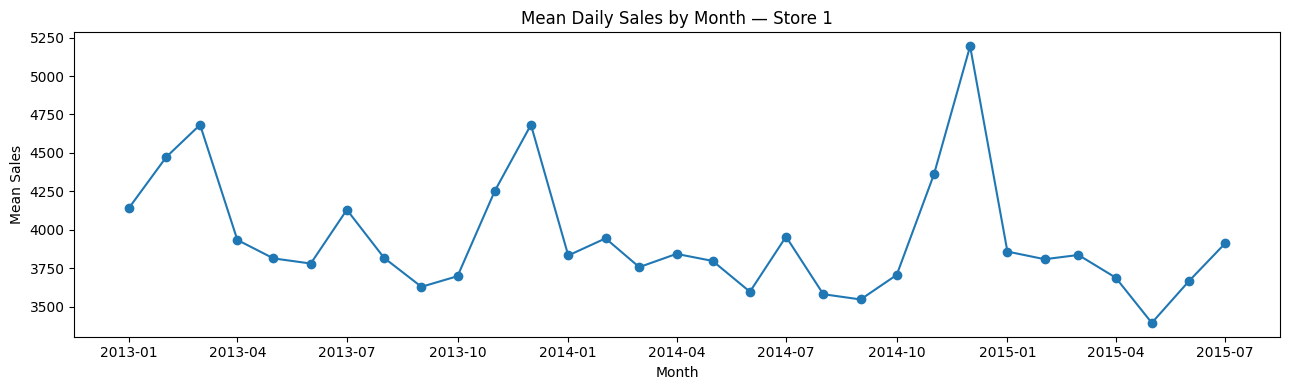

In [4]:
plot_df = train.dropna(subset=["Date", "Sales"]).sort_values("Date")
plt.figure(figsize=(13, 4))
plt.plot(plot_df["Date"], plot_df["Sales"], linewidth=0.8)
plt.title(f"Daily Sales — Store {STORE_ID}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

# Trung bình theo tháng để nhìn xu hướng/mùa vụ rõ hơn.
monthly_sales = plot_df.set_index("Date")["Sales"].resample("MS").mean()
plt.figure(figsize=(13, 4))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title(f"Mean Daily Sales by Month — Store {STORE_ID}")
plt.xlabel("Month")
plt.ylabel("Mean Sales")
plt.tight_layout()
plt.show()

## 5. Lịch, khuyến mãi và ngày lễ

Các biến dưới đây xuất hiện trong `features.py`. EDA chỉ so sánh mô tả; chênh lệch doanh thu không tự chứng minh quan hệ nhân quả.

Sales theo thứ trong tuần:


,count,mean,median
DayOfWeek_EDA,,,
1,134,"4,946.12","5,140.00"
2,135,"4,650.92","4,633.00"
3,135,"4,454.47","4,383.00"
4,135,"4,094.61","4,293.00"
5,135,"4,516.41","4,609.00"
6,134,"4,942.97","4,785.00"
7,134,0.00,0.00


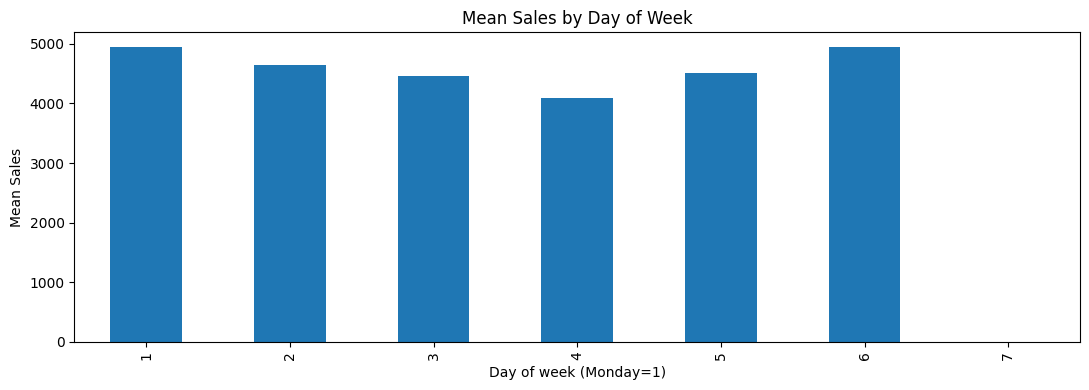

Sales theo tháng:


,count,mean,median
Month_EDA,,,
1,93,"3,944.59","4,546.00"
2,84,"4,075.48","4,624.50"
3,93,"4,091.97","4,583.00"
4,90,"3,821.73","4,298.00"
5,93,"3,668.39","4,431.00"
6,90,"3,681.41","4,165.00"
7,93,"3,998.95","4,359.00"
8,62,"3,698.77","4,082.00"
9,60,"3,587.75","3,952.50"


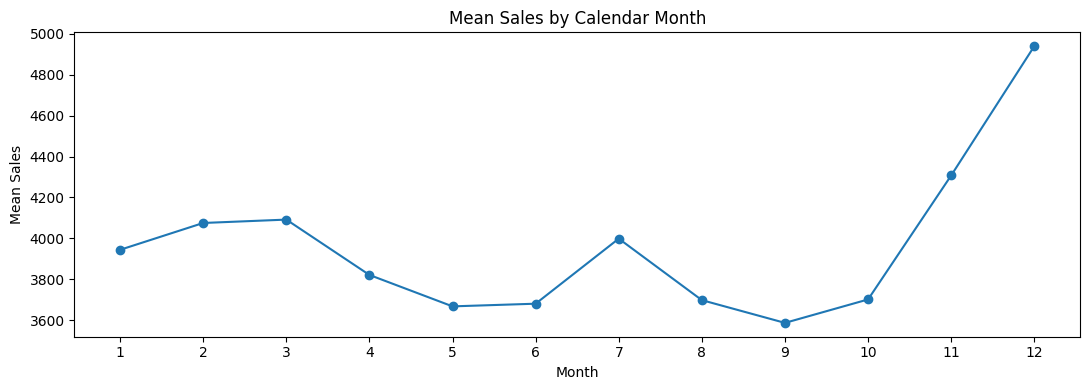

Sales theo Promo:


,count,mean,median
Promo,,,
0,582,"3,198.99","3,846.50"
1,360,"5,152.89","5,188.50"


Sales theo StateHoliday:


,count,mean,median
StateHoliday,,,
0,915,"4,062.14","4,413.00"
a,17,0.00,0.00
b,6,0.00,0.00
c,4,0.00,0.00


Sales theo SchoolHoliday:


,count,mean,median
SchoolHoliday,,,
1,193,"3,976.23","4,280.00"
0,749,"3,937.84","4,396.00"


In [5]:
# Tạo biến lịch tạm thời để phân tích; features.py sẽ tạo các feature dùng cho mô hình.
train["DayOfWeek_EDA"] = train["Date"].dt.dayofweek + 1  # Monday=1, Sunday=7
train["Month_EDA"] = train["Date"].dt.month

print("Sales theo thứ trong tuần:")
display(train.groupby("DayOfWeek_EDA")["Sales"].agg(
    count="count", mean="mean", median="median"
))
train.groupby("DayOfWeek_EDA")["Sales"].mean().plot(kind="bar")
plt.title("Mean Sales by Day of Week")
plt.xlabel("Day of week (Monday=1)")
plt.ylabel("Mean Sales")
plt.tight_layout()
plt.show()

print("Sales theo tháng:")
display(train.groupby("Month_EDA")["Sales"].agg(
    count="count", mean="mean", median="median"
))
train.groupby("Month_EDA")["Sales"].mean().plot(marker="o")
plt.title("Mean Sales by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Mean Sales")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

if "Promo" in train.columns:
    print("Sales theo Promo:")
    display(train.groupby("Promo", dropna=False)["Sales"].agg(
        count="count", mean="mean", median="median"
    ))

for col in ["StateHoliday", "SchoolHoliday"]:
    if col in train.columns:
        print(f"Sales theo {col}:")
        display(train.groupby(col, dropna=False)["Sales"].agg(
            count="count", mean="mean", median="median"
        ).sort_values("mean", ascending=False))

**Liên hệ với feature engineering:** `DayOfWeek`, `Month`, `Promo`, `StateHoliday` và `SchoolHoliday` là những biến đáng kiểm tra vì chúng được sử dụng hoặc chuyển đổi trong `features.py`. Việc mã hóa chu kỳ bằng sin/cos là quyết định biểu diễn dữ liệu; không cần EDA phải chứng minh trước rằng cách mã hóa này chắc chắn tốt hơn.

## 6. Kiểm tra tính liên tục của chuỗi thời gian

Hàm `make_sequences()` trong `features.py` chỉ giữ lại mẫu có các ngày liên tiếp. Vì vậy, cần kiểm tra khoảng cách giữa các ngày và số ngày bị thiếu trong lịch của Store 1.

In [6]:
dates = train["Date"].dropna().sort_values().drop_duplicates()
date_diffs = dates.diff().dt.days
print("Khoảng cách ngày giữa các bản ghi liên tiếp:")
display(date_diffs.dropna().value_counts().sort_index().rename("count").to_frame())

if not dates.empty:
    full_calendar = pd.date_range(dates.min(), dates.max(), freq="D")
    missing_dates = full_calendar.difference(pd.DatetimeIndex(dates))
    print("Số ngày trong lịch đầy đủ:", len(full_calendar))
    print("Số ngày thiếu trong dữ liệu:", len(missing_dates))
    if len(missing_dates):
        print("Một số ngày thiếu:", list(missing_dates[:10]))

Khoảng cách ngày giữa các bản ghi liên tiếp:


,count
Date,
1.00,941


Số ngày trong lịch đầy đủ: 942
Số ngày thiếu trong dữ liệu: 0


**Lưu ý:** không tự động tạo thêm ngày hoặc điền doanh thu cho ngày thiếu khi chưa xác định ý nghĩa của khoảng trống. Cần bảo đảm dữ liệu được sắp xếp theo `Date` trước khi tạo lag, rolling features và chuỗi LSTM.

## 7. Train/test và cách đánh giá

So sánh phạm vi ngày của Store 1. Với dữ liệu chuỗi thời gian, validation nên lấy một đoạn thời gian nằm sau train, không chia ngẫu nhiên.

In [7]:
print(f"Train: {train['Date'].min()} → {train['Date'].max()}")
if not test.empty:
    print(f"Test : {test['Date'].min()} → {test['Date'].max()}")
    print("Test bắt đầu sau ngày cuối train:", bool(test["Date"].min() > train["Date"].max()))

sorted_train = train.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)
if len(sorted_train) >= 10:
    split_idx = int(len(sorted_train) * 0.8)
    print("Ví dụ mốc validation (20% cuối theo thời gian):", sorted_train.loc[split_idx, "Date"])
    print("Số dòng trước mốc:", split_idx)
    print("Số dòng từ mốc trở đi:", len(sorted_train) - split_idx)

Train: 2013-01-01 00:00:00 → 2015-07-31 00:00:00
Test : 2015-08-01 00:00:00 → 2015-09-17 00:00:00
Test bắt đầu sau ngày cuối train: True
Ví dụ mốc validation (20% cuối theo thời gian): 2015-01-24 00:00:00
Số dòng trước mốc: 753
Số dòng từ mốc trở đi: 189


## 8. Kết luận EDA

Sau khi chạy notebook, hãy ghi kết luận dựa trên các con số và biểu đồ thực tế. Không nên ghi trước những kết luận chưa được dữ liệu xác nhận.

- **Phạm vi:** chỉ sử dụng Store 1; ghi lại số dòng train/test và khoảng thời gian.
- **Chất lượng dữ liệu:** ghi nhận missing values, ngày không hợp lệ, khóa trùng và doanh thu âm (nếu có).
- **Mẫu hình doanh thu:** mô tả xu hướng, biến động theo thứ trong tuần/tháng và các trường hợp Sales bằng 0.
- **Biến đầu vào:** nhận xét mô tả về Promo và các biến holiday; không diễn giải tương quan thành quan hệ nhân quả.
- **Chuỗi thời gian:** ghi rõ có hay không có ngày bị thiếu, vì điều này ảnh hưởng đến việc tạo sequence LSTM.
- **Bước tiếp theo:** dùng `data.py` để nạp/làm sạch/chia dữ liệu và `features.py` để tạo đặc trưng; đánh giá mô hình bằng cách chia theo thời gian.

> `Customers` chỉ được giữ để khám phá dữ liệu lịch sử. Vì không có trong test chính thức, không đưa biến này vào feature đầu vào khi dự báo test.